# Spreads souverains et risque politique en zone euro
Ce projet étudie l'écart de taux à 10 ans entre l'OAT française et le Bund allemand autour d'événements politiques français, ainsi que l'écart entre la France et l'Espagne.

## 1. Les données de taux

Toutes nos séries mesurent la même grandeur : le **rendement d'une obligation d'État à
10 ans**, en % par an. Nous en déduisons deux spreads, exprimés en points de base
(1 pb = 0,01 point de %) :

- **France-Allemagne** : taux de l'OAT moins taux du Bund ;
- **France-Espagne** : taux de l'OAT moins taux espagnol. Ce spread ne dépend pas du taux
  allemand, puisque FR-ES = (FR-DE) - (ES-DE).

Les deux jambes d'un spread viennent toujours de la même source (journal, D5) : sinon,
l'écart de méthode entre deux sources se mêlerait au spread.

### Sources envisagées

| Source | Pays | Fréquence | Ce que mesure le taux | Accès |
|---|---|---|---|---|
| BCE, jeu IRS | FR, DE, ES | mensuelle | taux à long terme du critère de convergence | API publique |
| Eurostat `irt_lt_mcby_d` | FR, DE, ES | quotidienne | même mesure que la BCE, en quotidien | copie DBnomics (l'API Eurostat ne la diffuse plus) |
| CNBC | FR, DE, ES | quotidienne | cotation indicative, clôture découpée à l'heure de New York | API non documentée, usage personnel et non commercial |
| Banque de France, TEC 10 | FR | quotidienne | OAT fictive d'échéance exactement 10 ans, interpolée | copie DBnomics |
| Bundesbank | DE | quotidienne | rendement à 10 ans lu sur une courbe des taux estimée | téléchargement CSV |
| Banco de España, TI 1.3 | ES | quotidienne | obligations de l'État à 10 ans, marché secondaire | téléchargement CSV |

Les méthodes de la Bundesbank et du Banco de España restent à confirmer dans leurs notes
méthodologiques.

In [1]:
import pandas as pd
from IPython.display import Image, display

from src.compare_sources import (
    SPREADS,
    compare_all,
    correlation_with_arbiter,
    coverage_table,
    gap_relative_to_spread,
    share_identical_days,
)
from src.figures import plot_arbiter_correlation, plot_change_correlation, plot_gaps_bp
from src.load_rates import (
    load_banco_de_espana,
    load_banque_de_france,
    load_bundesbank,
    load_cnbc,
    load_eurostat,
)

pd.set_option("display.precision", 2)

### Couverture des séries enregistrées dans `data/raw/`

Le tableau est recalculé à partir des fichiers bruts. Les barres CNBC du samedi et du
dimanche sont retirées (journal, D7).

In [2]:
coverage_table()

,source,pays,observations,début,fin
0,CNBC,FR,2810,2016-01-01,2026-10-22
1,CNBC,DE,2813,2016-01-01,2026-10-22
2,CNBC,ES,2813,2016-01-01,2026-10-22
3,Eurostat (copie DBnomics),FR,2361,2016-01-04,2025-03-31
4,Eurostat (copie DBnomics),DE,2347,2016-01-04,2025-04-04
5,Eurostat (copie DBnomics),ES,2347,2016-01-04,2025-04-04
6,"Banque de France, TEC 10",FR,2672,2016-01-04,2026-06-15
7,Bundesbank,DE,2686,2016-01-04,2026-08-03
8,"Banco de España, TI 1.3",ES,2767,2016-01-04,2026-10-21


**Lecture.** Seul CNBC couvre toute la période pour les trois pays. La série Eurostat
s'arrête en avril 2025 (journal, D4) ; les séries nationales s'arrêtent à des dates
différentes, la Banque de France la première (juin 2026).

### Test de faisabilité : contrôle par la série mensuelle de la BCE

Avant de télécharger les données, le script `scripts/check_sources.py` (exécuté en ligne
le 2026-10-23, il n'est pas relancé par ce notebook) a comparé la moyenne mensuelle de
chaque série quotidienne à la série mensuelle officielle de la BCE :

| Source | Début | Fin | Écart moyen à la BCE |
|---|---|---|---|
| BCE mensuelle (DE, FR, ES) | 2016-01 | 2026-09 | référence |
| Eurostat via DBnomics | 2016-01-04 | avril 2025 | 0,001 à 0,003 point de % |
| Banque de France TEC 10 | 2016-01-04 | 2026-06-15 | 0,020 point de % |
| Bundesbank 10 ans | 2016-01-04 | 2026-08-03 | 0,041 point de % |
| Banco de España 10 ans | 2016-01-04 | 2026-09-30 | 0,006 point de % |

Eurostat retombe presque exactement sur la BCE : c'est la même mesure. Les sources
nationales s'en écartent un peu plus, parce que leur taux est construit autrement.

## 2. Organisation du code

Seuls les scripts de `scripts/` se connectent à Internet. Ils enregistrent les réponses
brutes, sans les modifier, dans `data/raw/`, avec un fichier `metadata.csv` (URL, date de
téléchargement). Le notebook n'appelle que `src/`, qui lit ces fichiers : il s'exécute
donc hors ligne.

| Fichier | Rôle | Entrées → sorties |
|---|---|---|
| `scripts/check_sources.py` | test de faisabilité, en ligne | API → bilan affiché, rien n'est enregistré |
| `scripts/download_cnbc.py` | télécharge CNBC une fois | API CNBC → `data/raw/cnbc/FR10Y-FR.json`, `DE10Y-DE.json`, `ES10Y-ES.json`, `metadata.csv` |
| `scripts/download_eurostat.py` | télécharge Eurostat, référence de comparaison | DBnomics → `data/raw/eurostat/FR.json`, `DE.json`, `ES.json`, `metadata.csv` |
| `scripts/download_national.py` | télécharge les séries des banques centrales, arbitres | Banque de France, Bundesbank, Banco de España → `data/raw/nationales/`, `metadata.csv` |
| `src/load_rates.py` | lit les fichiers bruts, hors ligne | JSON ou CSV brut → `pd.Series` quotidienne (date → taux en %) |
| `src/compare_sources.py` | compare les sources | séries → tableaux d'écarts et de corrélations |
| `src/figures.py` | trace les figures | séries → `outputs/figures/*.png` |
| `docs/journal_decisions.md` | journal des décisions | critère écrit avant la comparaison, résultats, décisions, biais |

## 3. Choix de la source quotidienne

Une étude d'événements mesure la **variation** du spread autour d'une date. Il nous faut
donc une série quotidienne, homogène entre pays, relevée à la même heure pour tous, et
qui couvre 2024-2026. Eurostat est homogène mais s'arrête en avril 2025 ; CNBC va jusqu'en
2026 mais n'est pas une source publique. Nous avons comparé les deux.

### 3.1 Critère fixé avant la comparaison (journal, D7)

CNBC devient notre source si, pour chaque pays, sur les jours communs avec Eurostat :
l'écart absolu moyen des niveaux est inférieur à **3 pb** et la corrélation des variations
quotidiennes dépasse **0,95**. Le critère n'est pas totalement aveugle : une comparaison
rapide (D6) avait déjà montré un écart d'environ 4 pb sur l'Allemagne. Nous avons gardé
les seuils malgré tout.

In [3]:
compare_all()

,jours communs,écart moyen (pb),écart abs. moyen (pb),écart abs. max (pb),corr. variations,écart abs. moyen variations (pb),critère D7 respecté
FR,2356.0,0.13,0.83,16.9,0.93,1.07,False
DE,2346.0,4.36,5.02,24.5,0.50,3.31,False
ES,2344.0,1.29,4.01,25.6,0.38,3.81,False
FR-DE,2328.0,-4.23,4.97,25.5,0.30,3.36,NaN
FR-ES,2326.0,-1.16,4.09,31.2,0.21,3.92,NaN


**Lecture.** Le critère n'est respecté pour aucun pays. Les niveaux sont proches
(moins de 1 pb pour la France), mais les variations quotidiennes concordent mal : 0,50
pour l'Allemagne, 0,38 pour l'Espagne, 0,30 et 0,21 pour les deux spreads.

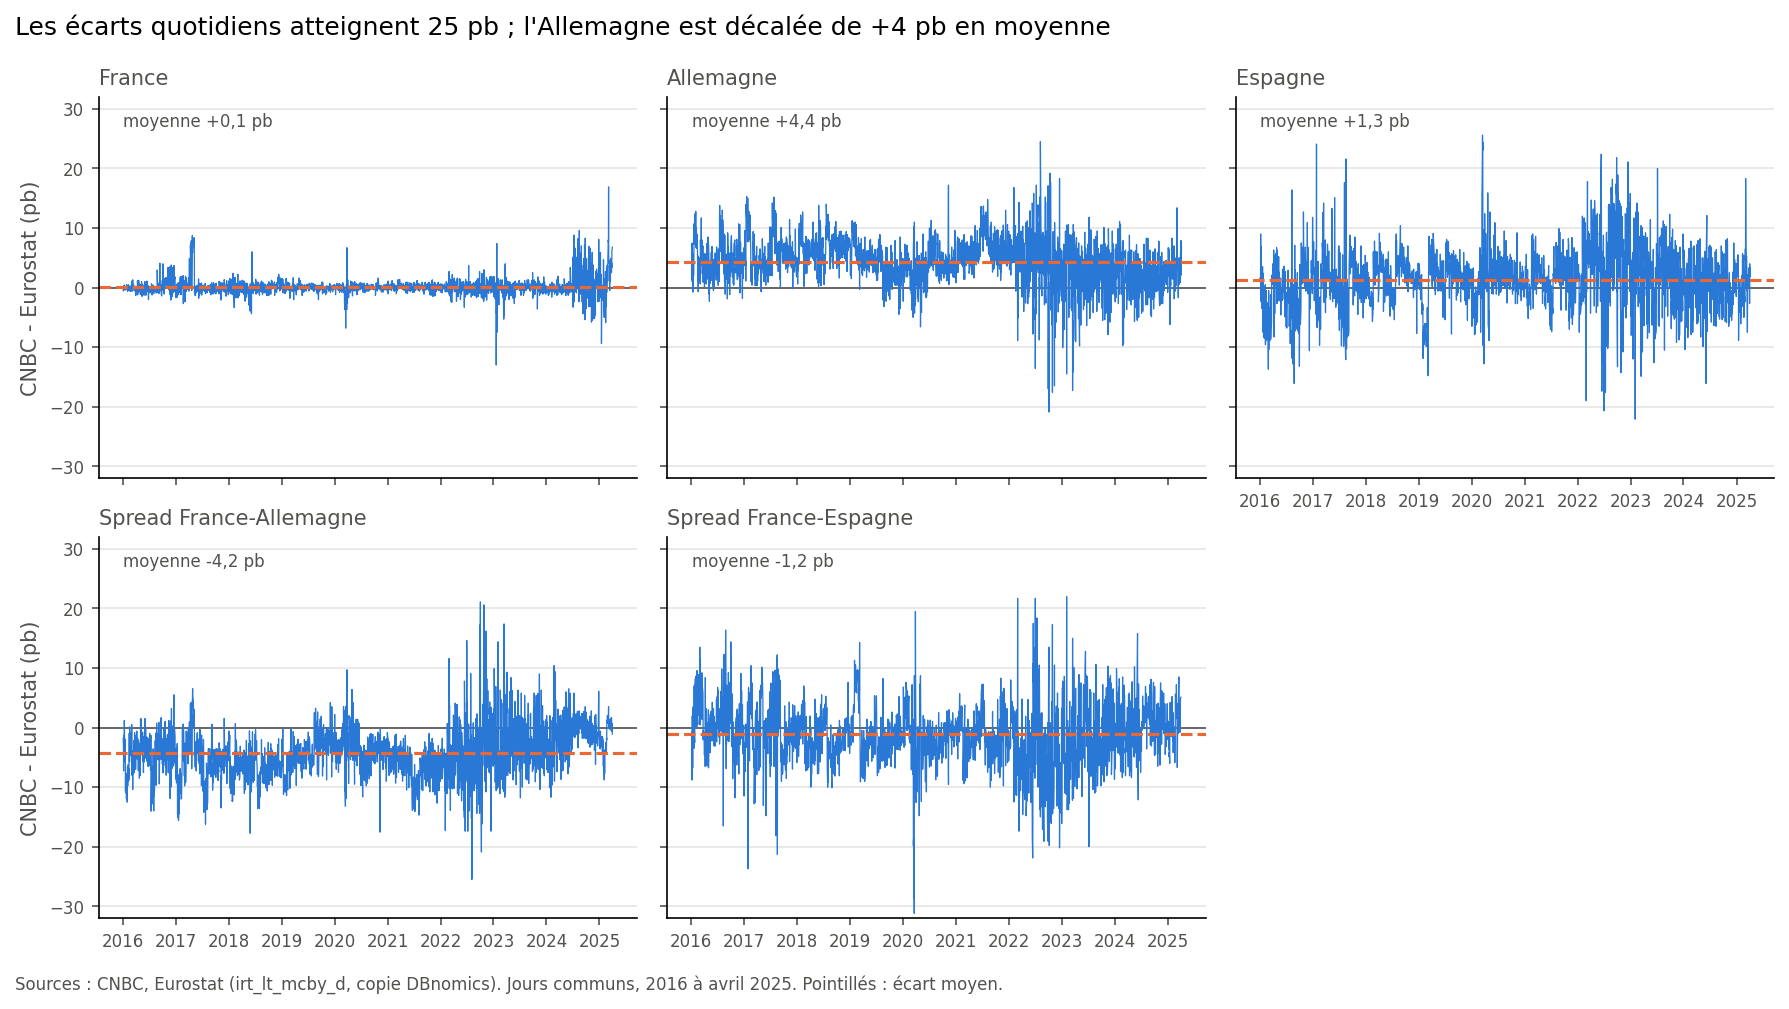

In [4]:
display(Image(filename=str(plot_gaps_bp())))

**Lecture.** L'Allemagne est décalée d'environ +4 pb en permanence ; des écarts ponctuels
atteignent 25 pb ; pour la France, l'écart s'élargit à partir de 2024.

### 3.2 Ces écarts sont-ils graves ? Comparaison à l'ordre de grandeur du spread

Nous rapportons l'écart à la taille du spread (en valeur absolue, car le spread
France-Espagne est négatif sur presque toute la période), puis le désaccord sur la
variation du jour à la variation typique du spread.

In [5]:
cnbc = {country: load_cnbc(symbol) for country, symbol in {"FR": "FR10Y-FR", "DE": "DE10Y-DE", "ES": "ES10Y-ES"}.items()}
eurostat = {country: load_eurostat(country) for country in ["FR", "DE", "ES"]}
for first, second in SPREADS:
    print(f"Spread {first}-{second} (pb, sauf mention)")
    display(gap_relative_to_spread(cnbc[first] - cnbc[second], eurostat[first] - eurostat[second]).round(1))

Spread FR-DE (pb, sauf mention)


,spread abs. moyen,écart abs. niveau,variation abs. du spread,écart abs. variations,écart / spread (%),écart / variation (%)
2016,37.6,4.6,3.2,3.2,12.3,100.1
2017,49.3,5.8,2.9,2.7,11.8,93.8
2018,38.6,6.7,2.4,2.4,17.4,100.8
2019,38.3,4.4,2.3,2.3,11.6,98.9
2020,36.6,4.1,3.0,2.8,11.2,94.9
2021,38.1,6.5,2.5,2.4,17.0,95.3
2022,55.9,6.2,6.3,6.1,11.0,96.0
2023,56.1,4.3,5.6,5.5,7.7,97.6
2024,64.6,2.7,3.3,3.2,4.2,97.3
2025,75.7,2.4,1.5,1.3,3.2,86.7


Spread FR-ES (pb, sauf mention)


,spread abs. moyen,écart abs. niveau,variation abs. du spread,écart abs. variations,écart / spread (%),écart / variation (%)
2016,92.7,3.7,4.6,4.2,4.0,90.6
2017,74.5,3.9,4.0,4.1,5.3,102.9
2018,64.0,3.1,2.9,2.7,4.8,93.5
2019,53.0,3.4,2.6,2.6,6.4,100.8
2020,52.0,3.6,2.9,3.1,6.9,107.8
2021,34.1,3.1,2.6,2.8,9.1,103.9
2022,48.0,7.5,6.3,6.4,15.6,101.9
2023,48.2,5.4,5.7,5.7,11.3,100.2
2024,21.0,3.3,3.8,3.9,15.6,103.9
2025,8.0,2.8,2.4,2.7,35.5,109.5


**Lecture.**

- **En niveau**, l'écart vaut en moyenne 11 % du spread France-Allemagne et 4 à 16 % du
  spread France-Espagne. C'est notable mais tolérable pour décrire une tendance. En 2025,
  le spread France-Espagne passe près de zéro et le rapport n'est plus interprétable.
- **En variation**, le désaccord entre les deux sources vaut 87 à 110 % de la variation
  typique du spread : le bruit entre sources a la taille du signal. Pour une étude
  d'événements, c'est rédhibitoire.

### 3.3 D'où vient le désaccord ? L'heure de relevé

Nous recalculons la corrélation des variations **mois par mois** (un mois comptant moins
de 15 variations n'est pas retenu ; une semaine, avec 4 ou 5 variations, serait trop
instable), en comparant aussi la barre CNBC datée J au taux Eurostat de J+1.

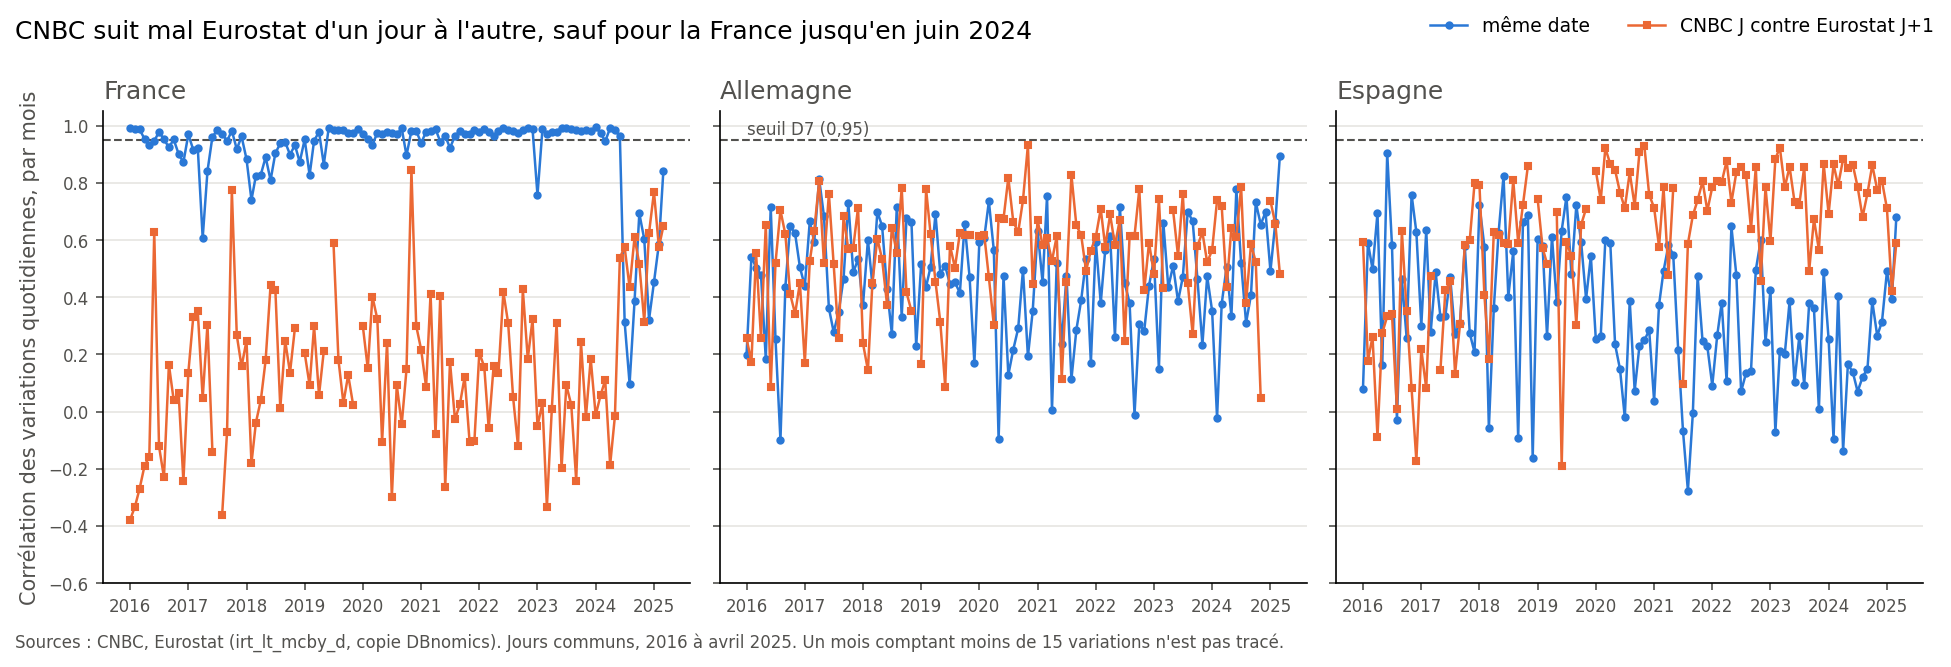

In [6]:
display(Image(filename=str(plot_change_correlation("M"))))

**Lecture.**

- **France** : CNBC suit Eurostat le même jour (0,94 à 0,99 de janvier à juin 2024), puis
  la corrélation chute à 0,31 en juillet 2024 et 0,10 en août 2024. La rupture est brutale
  et coïncide avec la dissolution (9 juin 2024) et les législatives anticipées (30 juin et
  7 juillet 2024).
- **Espagne** : à partir de 2020, la barre CNBC datée J correspond mieux au taux Eurostat
  de J+1 qu'à celui de J.
- **Allemagne** : aucun alignement satisfaisant, avec ou sans décalage. Notre hypothèse,
  non vérifiée : CNBC relève le taux allemand en fin de journée à New York, entre deux
  séances européennes.

Nous avons aussi cherché à reconstruire une clôture commune à 17 h 30, heure de Paris,
avec les barres de 5 minutes de CNBC. Les trois pays n'en ont le même jour qu'à partir de
mars 2026 : la piste est écartée (journal, D7).

### 3.4 Qui a tort ? Arbitrage par les banques centrales (journal, D9)

Nous comparons les variations de CNBC et d'Eurostat à celles d'une troisième source, la
banque centrale de chaque pays. Ces séries ne servent qu'à ce diagnostic.

In [7]:
arbiters = {"FR": load_banque_de_france(), "DE": load_bundesbank(), "ES": load_banco_de_espana()}
for country in ["FR", "DE", "ES"]:
    print(f"{country} : corrélation annuelle des variations avec {arbiters[country].name}")
    display(correlation_with_arbiter(cnbc[country], eurostat[country], arbiters[country], period="Y").T.round(2))

FR : corrélation annuelle des variations avec Banque de France


,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
CNBC,0.44,0.4,0.40,0.54,0.46,0.35,0.38,0.50,0.40,0.54,0.39
Eurostat,0.46,0.4,0.52,0.51,0.43,0.33,0.35,0.45,0.63,1.00,NaN


DE : corrélation annuelle des variations avec Bundesbank


,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
CNBC,0.47,0.54,0.54,0.49,0.54,0.46,0.41,0.53,0.49,0.57,0.49
Eurostat,0.97,0.96,0.98,0.96,0.96,0.96,0.99,0.99,0.99,0.99,NaN


ES : corrélation annuelle des variations avec Banco de España


,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
CNBC,0.49,0.28,0.38,0.34,0.43,0.22,0.24,0.11,0.13,0.37,0.46
Eurostat,0.86,0.89,0.88,0.78,0.89,0.83,0.87,0.82,0.83,0.81,NaN


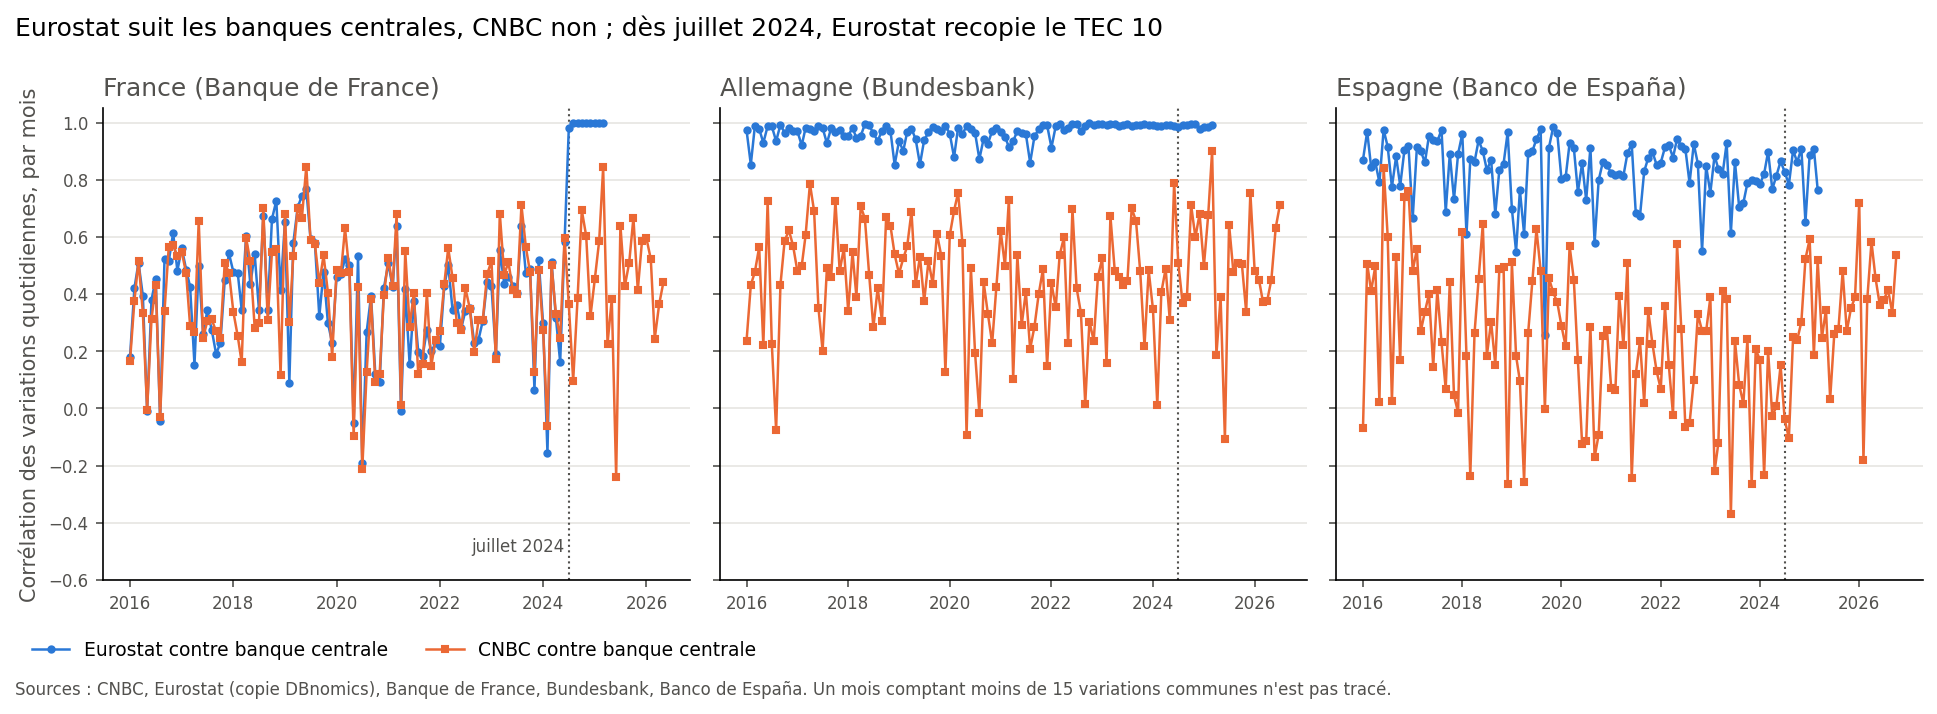

In [8]:
display(Image(filename=str(plot_arbiter_correlation())))

Pour la France, nous vérifions si Eurostat recopie le TEC 10 de la Banque de France :
part des jours où les deux séries sont égales à 0,05 pb près, mois par mois.

In [9]:
share_identical_days(eurostat["FR"], arbiters["FR"])["2024-01":].to_frame("part de jours identiques").T.round(2)

,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03
part de jours identiques,0.0,0.0,0.15,0.05,0.18,0.05,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


**Lecture.**

| | Eurostat contre banque centrale | CNBC contre banque centrale | Qui s'écarte |
|---|---|---|---|
| Allemagne (Bundesbank) | 0,96 à 0,99 | 0,41 à 0,57 | CNBC |
| Espagne (Banco de España) | 0,78 à 0,89 | 0,11 à 0,49 | CNBC |
| France avant juillet 2024 (TEC 10) | 0,33 à 0,52 | 0,35 à 0,54 | le TEC 10, sans doute relevé à une autre heure |
| France à partir de juillet 2024 | identique | environ 0,4, inchangé | Eurostat change de source |

À partir de juillet 2024, la série Eurostat pour la France **est** le TEC 10 de la Banque
de France. La rupture de juillet 2024 vient donc d'Eurostat, pas de CNBC.

### 3.5 Où en est-on

- CNBC n'est pas aligné sur les banques centrales pour l'Allemagne et l'Espagne : en
  l'état, il ne convient pas à une étude d'événements.
- Eurostat n'est pas homogène pour la France : il change de méthode en juillet 2024, au
  cœur de notre période, et s'arrête en avril 2025.
- Le choix de la source quotidienne reste ouvert. Toutes les étapes, et les biais qu'elles
  introduisent, sont consignées dans `docs/journal_decisions.md` (D4 à D9).